In [ ]:
import torch
from torch.distributions.multivariate_normal import MultivariateNormal
import math
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
import numpy as np
from torch import nn
import torch.optim as optim

def lorenz96_rhs(x, F = 8.0):
    """
    Lorenz-96 vector field.

    x: Tensor of shape (..., N)
    F: scalar or tensor broadcastable to x[..., 0]

    Returns: dx/dt with same shape as x
    """
    # Periodic neighbors using roll
    x_ip1 = torch.roll(x, shifts=-1, dims=-1)  # x_{i+1}
    x_im1 = torch.roll(x, shifts=+1, dims=-1)  # x_{i-1}
    x_im2 = torch.roll(x, shifts=+2, dims=-1)  # x_{i-2}

    # dx_i/dt = (x_{i+1} - x_{i-2}) * x_{i-1} - x_i + F
    return (x_ip1 - x_im2) * x_im1 - x + torch.as_tensor(F, device=x.device, dtype=x.dtype)


def rk4_step(
    x,
    dt,
    rhs=lorenz96_rhs,
    rhs_args = (),
    rhs_kwargs = None,
):
    """
    One Runge-Kutta 4 step: x_{n+1} = x_n + dt/6*(k1 + 2k2 + 2k3 + k4).
    """
    if rhs_kwargs is None:
        rhs_kwargs = {}

    k1 = rhs(x, *rhs_args, **rhs_kwargs)
    k2 = rhs(x + 0.5 * dt * k1, *rhs_args, **rhs_kwargs)
    k3 = rhs(x + 0.5 * dt * k2, *rhs_args, **rhs_kwargs)
    k4 = rhs(x + dt * k3, *rhs_args, **rhs_kwargs)

    return x + (dt / 6.0) * (k1 + 2.0 * k2 + 2.0 * k3 + k4)


@torch.no_grad()
def integrate_lorenz96(
    x0,
    dt,
    steps,
    F = 8.0,
    save_every= 1,
):
    """
    Integrate Lorenz-96 forward with RK4.

    x0: (..., N) initial condition
    dt: timestep
    steps: number of RK4 steps
    F: forcing
    save_every: store every k-th step (including step 0)

    Returns:
      traj: (T, ..., N) where T = steps//save_every + 1
    """
    x = x0.clone()
    out = [x0.clone()]
    

    rhs_kwargs = {"F": F}
    for s in range(1, steps + 1):
        x = rk4_step(x, dt, rhs=lorenz96_rhs, rhs_kwargs=rhs_kwargs)
        if (s % save_every) == 0:
            out.append(x.clone())

    return torch.stack(out, dim=0)


def henon(x0, steps, a= 1.4,b= 0.3, save_every =1):
    sol = torch.zeros(steps+1,2)
    sol[0,:] = x0
    
    for s in range(1,steps+1):
        sol[s,0] = 1.0 - a*sol[s-1,0]**2+sol[s-1,1]
        sol[s,1] = b*sol[s-1,0]
    
    return sol

# Example usage:
if __name__ == "__main__":
    device = "cuda" if torch.cuda.is_available() else "cpu"
    dtype = torch.float32

    B_L, N_L = 100, 40
    T_full = 550
    T_train = 500
    high_lorenz = 10
    low_lorenz = 6
    lorenz_traj = torch.zeros(T_full+1,B_L,N_L)
    F_list = torch.zeros(B_L)
    
    for i in range(B_L):
        x0 = torch.randn(N_L, device=device, dtype=dtype)
        F_list[i] = (high_lorenz-low_lorenz)*torch.rand(1)+low_lorenz
        lorenz_traj[:,i,:] = integrate_lorenz96(x0, dt=0.01, steps=T_full, F=F_list[i], save_every=1)
        
    B_H = 30
    steps_henon = 200
    
    henon_traj = torch.zeros(steps_henon+1,B_H,2)
    henon_params = torch.zeros(B_H,2)
    high_henon_a = 6
    low_henon_a = 6
    high_henon_b = 0.9
    low_henon_b = 0.9

    
    for i in range(B_H):
        x0 = torch.zeros(2)
        
        henon_params[i,0] = (high_henon_a-low_henon_a)*torch.rand(1)+low_henon_a
        henon_params[i,1] = (high_henon_b-low_henon_b)*torch.rand(1)+low_henon_b
        henon_traj[:,i,:] = henon(x0,steps_henon,henon_params[i,0],henon_params[i,1])

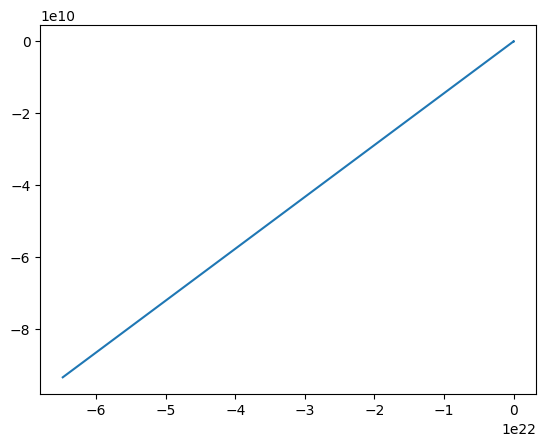

In [87]:
plt.plot(henon_traj[:,0,0],henon_traj[:,0,1])

In [88]:
def pairwise_distances(X,Y):
    
    distance = torch.cdist(X,Y)
    
    return distance

def laplace_matrix(X,Y,sigma=1):
    
    D = pairwise_distances(X, Y)
    matrix = torch.exp(-D/sigma)
    
    return matrix

def gaussian_matrix(X,Y,sigma=1):
    
    D = pairwise_distances(X, Y)
    matrix = torch.exp(-D**2/(2*sigma**2))
    
    return matrix

def gaussian_prod_matrix(X,Y,sigma_u=1,sigma_F=1):
    
    D1 = pairwise_distances(X[:,:-1], Y[:,:-1])
    matrix1 = torch.exp(-D1**2/(2*sigma_u**2))

    D2 = pairwise_distances(X[:,-1][:,None], Y[:,-1][:,None])
    matrix2 = torch.exp(-D2**2/(2*sigma_F**2))
    
    matrix = matrix1+matrix2
    
    return matrix

def matern52_matrix(X,Y,sigma=1):
    
    D = pairwise_distances(X, Y)
    matrix = (1+math.sqrt(5)*D/sigma+5.0/3.0*D**2/sigma**2)*torch.exp(-math.sqrt(5)*D/sigma)
    
    return matrix

def poly_matrix(X,Y,c=0,d=1):
    
    inner = X @ Y.T
    
    matrix = (c+inner)**d
    
    return matrix

In [ ]:
class FoundationModel(torch.nn.Module):
    
    def __init__(self,kernel_keyword,Eta,U,Y, r=32,r_p = 20, q=16,m=32,minibatch_prop=0.3,device=torch.device("cpu")):
        super().__init__()
        self.kernel = kernel_keyword
        self.r = r
        self.r_p = r_p
        self.q = q
        self.m = m
        self.minibatch_prop = minibatch_prop
        self.device = device
        self.d_in = self.r+self+r_p+self.q
        
        self.W_r = torch.nn.Parameter(torch.zeros((self.m,self.d_in), dtype=torch.float32),requires_grad=True)
        self.W_u = torch.nn.Parameter(torch.zeros((self.m,self.d_in), dtype=torch.float32),requires_grad=True)
        self.W_h = torch.nn.Parameter(torch.zeros((self.m,self.d_in), dtype=torch.float32),requires_grad=True)

        self.U_r = torch.nn.Parameter(torch.zeros((self.m,self.m), dtype=torch.float32),requires_grad=True)
        self.U_u = torch.nn.Parameter(torch.zeros((self.m,self.m), dtype=torch.float32),requires_grad=True)
        self.U_h = torch.nn.Parameter(torch.zeros((self.m,self.m), dtype=torch.float32),requires_grad=True)

        self.b_r = torch.nn.Parameter(torch.zeros((self.m,), dtype=torch.float32),requires_grad=True)
        self.b_u = torch.nn.Parameter(torch.zeros((self.m,), dtype=torch.float32),requires_grad=True)
        self.b_h = torch.nn.Parameter(torch.zeros((self.m,), dtype=torch.float32),requires_grad=True)


        self.adapters = nn.ModuleDict({
        "Henon": nn.Linear(2, 32),
        "L96": nn.Linear(40, 32),
        "AllenCahn": nn.Linear(128, 32),})
    
    def A(self,u):
        tokenizer = torch.zeros(self.r)
        
        for i in range(self.r):
            tokenizer[i] = 0.0        
        
        return tokenizer
    
    def GRU(self,W_r,W_u,W_h,U_r,U_u,U_h,b_r,b_u,b_h):
        
        r = nn.Sigmoid(W_r@tau+U_r@h+b_r)
        u = nn.Sigmoid(W_u@tau+U_u@h+b_u)
        h_hat = nn.Tanh(W_h@tau+U_h@(r*h)+b_h)
        h = u*h + (1-u)*h_hat
        
        return h

    
    def adapt(self, x, family):
        return self.adapters[family](x)
    
    def kernel_regression(X_test,X_train,Y_train,lam=10**-5,kernel=gaussian_matrix, **kernel_params):
    
        K_test = kernel(X_test,X_train, **kernel_params)
        K_train = kernel(X_train,X_train, **kernel_params)
        I = torch.eye(K_train.shape[0], device=K_train.device, dtype=K_train.dtype)

        alpha = torch.linalg.solve(K_train + lam * I, Y_train)

        Y_test = K_test @ alpha

        return Y_test
    
    def mse(Y_pred,Y_true):
        
        error = torch.linalg.norm(Y_true-Y_pred)/len(Y_true)
        
        return error